In [2]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

#load data

df = sns.load_dataset('tips')

print("ORIGINAL DATA:")
print(f"Total Rows: {len(df)}")
print(df.head())



ORIGINAL DATA:
Total Rows: 244
   total_bill   tip     sex smoker  day    time  size
0       16.99  1.01  Female     No  Sun  Dinner     2
1       10.34  1.66    Male     No  Sun  Dinner     3
2       21.01  3.50    Male     No  Sun  Dinner     3
3       23.68  3.31    Male     No  Sun  Dinner     2
4       24.59  3.61  Female     No  Sun  Dinner     4


In [5]:
#Filter One: Tips greater than $5

#df['tip'] > 5 creates True/False for each row

generous_tippers = df[df['tip'] > 5]

print("\n--- Generous Tippers (tip > $5)---")
print(f"Count: {len(generous_tippers)}")
print(generous_tippers[['total_bill', 'tip', 'day']].head())


--- Generous Tippers (tip > $5)---
Count: 18
    total_bill   tip  day
23       39.42  7.58  Sat
44       30.40  5.60  Sun
47       32.40  6.00  Sun
52       34.81  5.20  Sun
59       48.27  6.73  Sat


In [8]:
#Filter Two; Saturday dinners only

saturday_dinner = df[(df['day'] == 'Sat') & (df['time'] == 'Dinner')]

print("\n----Saturday Dinners----")
print(f"Count: {len(saturday_dinner)}")
print(saturday_dinner.head())


----Saturday Dinners----
Count: 87
    total_bill   tip     sex smoker  day    time  size
19       20.65  3.35    Male     No  Sat  Dinner     3
20       17.92  4.08    Male     No  Sat  Dinner     2
21       20.29  2.75  Female     No  Sat  Dinner     2
22       15.77  2.23  Female     No  Sat  Dinner     2
23       39.42  7.58    Male     No  Sat  Dinner     4


In [13]:
#Filter Three: Bills between $10 and $20

medium_bills = df[(df['total_bill'] >= 10) & (df['total_bill'] <= 20)]
print("\n ---- Medium Bills ($10 - $20---)")
print(f"Count: {len(medium_bills)}")
print(f"Average Tip: ($){medium_bills['tip'].mean():.2f}")
print(medium_bills.head())


 ---- Medium Bills ($10 - $20---)
Count: 130
Average Tip: ($)2.46
    total_bill   tip     sex smoker  day    time  size
0        16.99  1.01  Female     No  Sun  Dinner     2
1        10.34  1.66    Male     No  Sun  Dinner     3
8        15.04  1.96    Male     No  Sun  Dinner     2
9        14.78  3.23    Male     No  Sun  Dinner     2
10       10.27  1.71    Male     No  Sun  Dinner     2


In [16]:
#Filter Four: All tips less than $2

low_tips = df[df['tip'] < 2]
print(f"\n---Low Tips(<$2)----: {len(low_tips)} ")
print(low_tips)


---Low Tips($)----: 45 
     total_bill   tip     sex smoker   day    time  size
0         16.99  1.01  Female     No   Sun  Dinner     2
1         10.34  1.66    Male     No   Sun  Dinner     3
8         15.04  1.96    Male     No   Sun  Dinner     2
10        10.27  1.71    Male     No   Sun  Dinner     2
12        15.42  1.57    Male     No   Sun  Dinner     2
16        10.33  1.67  Female     No   Sun  Dinner     3
30         9.55  1.45    Male     No   Sat  Dinner     2
43         9.68  1.32    Male     No   Sun  Dinner     2
53         9.94  1.56    Male     No   Sun  Dinner     2
57        26.41  1.50  Female     No   Sat  Dinner     2
58        11.24  1.76    Male    Yes   Sat  Dinner     2
62        11.02  1.98    Male    Yes   Sat  Dinner     2
67         3.07  1.00  Female    Yes   Sat  Dinner     1
70        12.02  1.97    Male     No   Sat  Dinner     2
75        10.51  1.25    Male     No   Sat  Dinner     2
82        10.07  1.83  Female     No  Thur   Lunch     1
92    

In [20]:
#Filter Five: Sunday lunches

sunday_lunches = df[(df['day'] == 'Sun') & (df['time'] == 'Lunch')]
print("\n---Sunday Lunches---")
print(f"Count: {len(sunday_lunches)}")

# To check days that exist in dataset


---Sunday Lunches---
Count: 0


In [23]:
#To check days that exist in dataset
print("Days in Dataset")
print(df['day'].value_counts())

Days in Dataset
day
Sat     87
Sun     76
Thur    62
Fri     19
Name: count, dtype: int64


In [27]:
# To check what time exists
print("Times in Dataset")
print(df['time'].value_counts())


Times in Dataset
time
Dinner    176
Lunch      68
Name: count, dtype: int64


In [28]:
#To check the combination
print("Day + Time Combinations:")
print(df.groupby(['day', 'time']).size())

Day + Time Combinations:
day   time  
Thur  Lunch     61
      Dinner     1
Fri   Lunch      7
      Dinner    12
Sat   Dinner    87
Sun   Dinner    76
dtype: int64


In [30]:
#Filter Six: Find bills over $30 with tips over $5
medium_bills = df[(df['total_bill'] > 30) & (df['tip'] > 5)]
print("Medium Bills:")
print(f"Count: {len(medium_bills)}")
print(medium_bills)

Medium Bills:
Count: 9
     total_bill    tip     sex smoker   day    time  size
23        39.42   7.58    Male     No   Sat  Dinner     4
44        30.40   5.60    Male     No   Sun  Dinner     4
47        32.40   6.00    Male     No   Sun  Dinner     4
52        34.81   5.20  Female     No   Sun  Dinner     4
59        48.27   6.73    Male     No   Sat  Dinner     4
85        34.83   5.17  Female     No  Thur   Lunch     4
141       34.30   6.70    Male     No  Thur   Lunch     6
170       50.81  10.00    Male    Yes   Sat  Dinner     3
212       48.33   9.00    Male     No   Sat  Dinner     4


In [31]:
#Part Two: Functions

In [32]:
#Function One: Simple Calculation

def add_tax(bill_amount):
    """Add 7% tax to a bill"""
    tax = bill_amount * 0.07
    total = bill_amount + tax
    return total

#test one
my_bill = 50.00
final = add_tax(my_bill)
print(f"My Bill: ${my_bill}, With tax: ${final:.2f}")

My Bill: $50.0, With tax: $53.50


In [33]:
#Function Two: With muiltiple inputs

def calculate_tip(bill, tip_percent):
    """Calculate Tip Amount"""
    tip = bill * (tip_percent / 100)
    return tip

#Test Two

bill = 80.00
tip_15 = calculate_tip(bill, 15)
tip_20 = calculate_tip(bill, 20)

print(f"\n${bill} bill:")
print(f" 15% Tip: ${tip_15:.2f}")
print(f" 20% Tip: ${tip_20:.2f}")

    
    
    


$80.0 bill:
 15% Tip: $12.00
 20% Tip: $16.00


In [35]:
#Function Three: Educational Examples
def grade_score(score):
    """Convert number scores to letter grades"""
    if score >= 90:
        return "A"
    elif score >= 80:
        return "B"
    elif score >= 70:
        return "C"
    elif score >= 60:
        return "D"
    else:
        return "F"

#Testing

print(f"\nScore 95 = Grade {grade_score(95)}")
print(f"Score 82 = Grade {grade_score(82)}")
print(f"Score 67 = Grade { grade_score(67)}")        
    


Score 95 = Grade A
Score 82 = Grade B
Score 67 = Grade D


In [36]:
#Part Three : APPLY FUNCTIONS TO DATASETS

In [37]:
# create a function
def add_tax(bill):
    """Add 7% Tax"""
    return bill * 1.07

# apply to entire column(all 244 rows at once)
df['bill_with_tax'] = df['total_bill'].apply(add_tax)
print("First 10 rows with new tax column")
print(df[['total_bill', 'bill_with_tax']].head(10))

First 10 rows with new tax column
   total_bill  bill_with_tax
0       16.99        18.1793
1       10.34        11.0638
2       21.01        22.4807
3       23.68        25.3376
4       24.59        26.3113
5       25.29        27.0603
6        8.77         9.3839
7       26.88        28.7616
8       15.04        16.0928
9       14.78        15.8146


In [39]:
# example two: categorize tips

def tip_category(tip_amount):
    """Categorize tips as Low, Medium, High"""
    if tip_amount < 2:
        return "Low"
    elif tip_amount < 4:
        return "Medium"
    else:
        return "High"
# apply to all rows
df['tip_category'] = df['tip'].apply(tip_category)

print("\nTip Categories:")
print(df[['tip', 'tip_category']].head(20))


Tip Categories:
     tip tip_category
0   1.01          Low
1   1.66          Low
2   3.50       Medium
3   3.31       Medium
4   3.61       Medium
5   4.71         High
6   2.00       Medium
7   3.12       Medium
8   1.96          Low
9   3.23       Medium
10  1.71          Low
11  5.00         High
12  1.57          Low
13  3.00       Medium
14  3.02       Medium
15  3.92       Medium
16  1.67          Low
17  3.71       Medium
18  3.50       Medium
19  3.35       Medium


In [40]:
# count how many in each category
print("Category Counts")
print(df['tip_category'].value_counts())

Category Counts
tip_category
Medium    146
High       53
Low        45
Name: count, dtype: int64


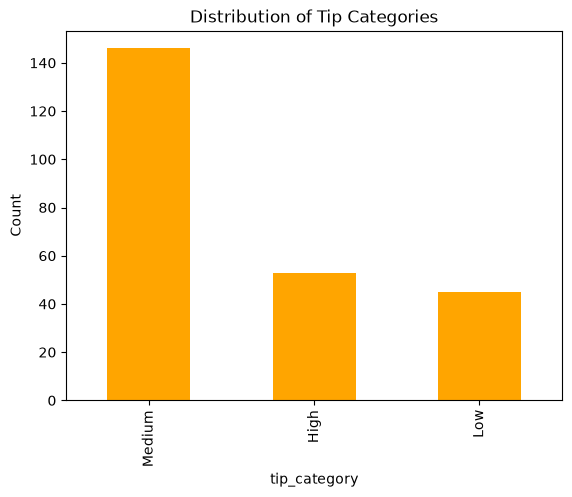

In [43]:
# to visualize the data

df['tip_category'].value_counts().plot(kind='bar', color='orange')
plt.title('Distribution of Tip Categories')
plt.ylabel('Count')
plt.show()

In [46]:
# Educational example

student_data = {
    'student_id': [1,2,3,4,5,6,7,8,9,10],
    'math_score': [95, 67, 88, 45, 72, 91, 58, 83, 77, 92],
    'reading_score': [88, 72, 91, 52, 68, 95, 61, 87, 82, 89]   
}

students = pd.DataFrame(student_data)
# use the grade_score function on all the students
students['math_grade'] = students['math_score'].apply(grade_score)
students['reading_grade'] = students['reading_score'].apply(grade_score)

print("Students's Grades")
print(students)

Students's Grades
   student_id  math_score  reading_score math_grade reading_grade
0           1          95             88          A             B
1           2          67             72          D             C
2           3          88             91          B             A
3           4          45             52          F             F
4           5          72             68          C             D
5           6          91             95          A             A
6           7          58             61          F             D
7           8          83             87          B             B
8           9          77             82          C             B
9          10          92             89          A             B


In [47]:
# how many got A's in Maths?

a_students = students[students['math_grade'] == 'A']
print(f"Students With A in Math: {len(a_students)}")

Students With A in Math: 3
